# D4_switching_main — Kobayashi方式：D4符号へのcode switchingによる $|T_L\rangle$ 生成の資源計数

**目的**：Kobayashi–Zhu–Hsin [KZH] のプロトコル（folded surface code (FSC) → D4符号 → transversal $U$（論理 $T^\dagger$）→ FSC）を、境界付き正方格子上で**ゲートレベルの回路として構成**し、段階ごとの物理量子ビット数・ラウンド数・物理時間・時空間体積・ゲート内訳を数える。

**このノートでは正しさの検証はしない**（→ `D4_switching_validation.ipynb`）。ここで数えた回路が正しい論理操作を実装していることは、検証ノートで別途確認する。

**理想条件**：物理ノイズ0。測定結果のランダム性は残る（$S^g_X$ の結果 $m_v$、$Z^g$ の結果）。

### プロトコル（[KZH] 本文 p.4 の手順 1–4、SM Sec. V A）と本研究での段階分け
| 段階 | 内容 | 根拠 | 時間 |
|---|---|---|---|
| S0 | FSC の $\overline{|+\rangle}$ 準備（$r,b$ を $|+\rangle$、$g$ を $|0\rangle$）。ノイズなしでは Z-plaquette のランダムな結果を $X$ で補正 | [KZH] 手順1（準備方法は記述なし） | `FT_ref`: $\lceil\kappa_0 d\rceil$ ラウンド（**仮定**）、`NL_min`: 1 |
| S1 | 全D4安定化子（$S^g_X$ を含む）の測定 = gauging | [KZH] 手順2「$O(d)$ rounds」 | `FT_ref`: $\lceil\kappa_{in} d\rceil$（**仮定**）、`NL_min`: $S^g_X$ のみ1ラウンド |
| S2 | $U = WV$（式(5)(8)） | [KZH] 手順3 | 定数深さ |
| S3 | $Z^g_e$ 測定 → $\prod_{v\in\kappa}S^g_{X;v}$ の CZ 部分で補正 | [KZH] 手順4 | 定数深さ |
| S4 | FSC のEC | [KZH] 手順4「$O(d)$ rounds」 | `FT_ref`: $\lceil\kappa_{out} d\rceil$（**仮定**）、`NL_min`: 0 |
| S5 | 論理 $\bar X$（Pauliフレーム）で $T^\dagger|+\rangle\to T|+\rangle$ | 本研究 | 0 |
| S6 | FSC → 通常の回転表面符号パッチ（比較Bのみ） | **未解決** | 除外（下界） |

ノイズなしで必要な追加処理（検証ノートで正しさを確認）：$m_v=1$ に対する $Z^rZ^b$ 文字列による補正は Pauli フレームで行う（物理コスト0）。

**距離**：$L=d$（FSC の $Z$ 距離が $L$、$X$型シフト距離が $L+3$ であることを下で MILP により確認）。

In [1]:
# ==== 環境設定（Google Colab / ローカル共通）====
# このノートブックは単独で実行できる（共通コードは下に埋め込まれており、他のファイルを読み込まない）。
# 出力（results/, figures/）はこのランタイムの作業ディレクトリに保存される。Colab ではランタイム終了で
# 消えるので、残したい場合は Google Drive を使う：
#   from google.colab import drive; drive.mount('/content/drive')
#   os.makedirs('/content/drive/MyDrive/D4_vs_MSD', exist_ok=True); os.chdir('/content/drive/MyDrive/D4_vs_MSD')
import os, sys, subprocess, json
IN_COLAB = 'google.colab' in sys.modules
RESULTS, FIGURES = 'results', 'figures'
os.makedirs(RESULTS, exist_ok=True); os.makedirs(FIGURES, exist_ok=True)
SEED = 20261024
print('cwd =', os.getcwd(), '| Colab =', IN_COLAB)

cwd = /tmp/claude-0/-home-user-2026-10-24-StudyWithClaude/fee9d03f-2fbf-502f-b670-8966176acf54/scratchpad/isolated/D4_switching_main | Colab = False


In [2]:
# ==== 外部ライブラリ（Colab に無いものだけをインストール）====
import importlib.util
for _mod, _pkg in [('stim', 'stim'), ('scipy', 'scipy'), ('sympy', 'sympy'), ('pandas', 'pandas'),
                   ('matplotlib', 'matplotlib')]:
    if importlib.util.find_spec(_mod) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', _pkg], check=True)
import numpy as np, pandas as pd, scipy
print('numpy', np.__version__, '| scipy', scipy.__version__, '| pandas', pd.__version__)

numpy 2.5.3 | scipy 1.18.1 | pandas 3.0.5


In [3]:
# ==== 図のスタイル（明るい背景・細い線・識別は色＋線種＋マーカー）====
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
                     'axes.edgecolor': '#52514e', 'axes.labelcolor': '#0b0b0b', 'text.color': '#0b0b0b',
                     'xtick.color': '#52514e', 'ytick.color': '#52514e', 'axes.grid': True,
                     'grid.color': '#e4e3df', 'grid.linewidth': 0.8, 'lines.linewidth': 2,
                     'lines.markersize': 7, 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.size': 10, 'legend.frameon': False})
C_KOB, C_LIT, C_AUX = '#2a78d6', '#eb6834', '#1baf7a'     # categorical slots 1,2,3 (validated palette)
C_R, C_G, C_B = '#e34948', '#008300', '#2a78d6'            # colours of the r, g, b qubit species

## 共通ライブラリ（埋め込み・関数定義のみ）
Google Colab ではノートブックごとに別のランタイムで実行されるため、他のファイルを読み込まずに済むよう、共通コードをこのノートブックに埋め込んでいる（各ノートの共通コードは同一のソースから自動生成されており、内容は一致する）。
**このセクションは上から順に実行するだけでよく、編集する必要はない**（Colab では見出しの左の三角で折りたためる）。

### 共通ライブラリ（F2 線形代数・ゲート／ガジェット・スケジューラ・Clifford+T 分解・計数ルール R1–R3）

In [4]:
"""common_lib: F2 linear algebra, gate/gadget model, scheduler, decompositions, cost model rules."""
import itertools, math
import numpy as np
from collections import Counter, defaultdict

In [5]:
# ---------------------------------------------------------------- F2 algebra
def f2_rref(M):
    """Row-reduce a uint8 matrix over F2. Returns (R, pivot_cols)."""
    M = (np.array(M, dtype=np.uint8) & 1).copy()
    rows, cols = M.shape
    piv = []
    r = 0
    for c in range(cols):
        if r >= rows:
            break
        nz = np.nonzero(M[r:, c])[0]
        if len(nz) == 0:
            continue
        p = r + nz[0]
        if p != r:
            M[[r, p]] = M[[p, r]]
        others = np.nonzero(M[:, c])[0]
        others = others[others != r]
        if len(others):
            M[others] ^= M[r]
        piv.append(c)
        r += 1
    return M[:r], piv


def f2_rank(M):
    if len(M) == 0:
        return 0
    return len(f2_rref(M)[1])


def f2_nullspace(M, n=None):
    """Basis (rows) of {x : M x = 0} over F2."""
    M = np.array(M, dtype=np.uint8)
    if M.size == 0:
        return np.eye(n, dtype=np.uint8)
    n = M.shape[1]
    Rm, piv = f2_rref(M)
    free = [c for c in range(n) if c not in set(piv)]
    basis = []
    for f in free:
        v = np.zeros(n, dtype=np.uint8)
        v[f] = 1
        for i, p in enumerate(piv):
            if Rm[i, f]:
                v[p] = 1
        basis.append(v)
    return np.array(basis, dtype=np.uint8).reshape(len(basis), n)


def f2_in_rowspace(Rref, piv, v):
    """Is v in the row space of the RREF matrix Rref (pivots piv)?"""
    v = np.array(v, dtype=np.uint8) & 1
    w = v.copy()
    for i, p in enumerate(piv):
        if w[p]:
            w ^= Rref[i]
    return not w.any()


def f2_solve(A, b):
    """Solve x A = b (x row vector, A rows = generators). Returns x or None."""
    A = np.array(A, dtype=np.uint8)
    m, n = A.shape
    aug = np.concatenate([A, np.eye(m, dtype=np.uint8)], axis=1)
    Rm, piv = f2_rref(aug)
    w = np.concatenate([np.array(b, dtype=np.uint8) & 1, np.zeros(m, dtype=np.uint8)])
    for i, p in enumerate(piv):
        if p >= n:
            break
        if w[p]:
            w ^= Rm[i]
    if w[:n].any():
        return None
    return w[n:]




import itertools
from collections import Counter, defaultdict

ARITY = {'INIT_X': 1, 'INIT_Z': 1, 'MEAS_X': 1, 'MEAS_Z': 1, 'H': 1, 'X': 1, 'Z': 1, 'S': 1, 'SDG': 1,
         'T': 1, 'TDG': 1, 'CNOT': 2, 'CZ': 2, 'CS': 2, 'CSDG': 2, 'CCZ': 3}
NONCLIFFORD = {'T', 'TDG', 'CS', 'CSDG', 'CCZ'}

In [6]:
# ------------------------------------------------------------------ minimum-weight logical (MILP)
def min_weight_odd(Hc, lvec, cols):
    """min |x| over x in F2^cols with Hc x = 0 and lvec . x = 1 (exact MILP, HiGHS)."""
    from scipy.optimize import milp, LinearConstraint, Bounds
    H = np.array(Hc, dtype=float)[:, cols]
    H = H[np.any(H, axis=1)]
    l = np.array(lvec, dtype=float)[cols]
    m, n = H.shape
    # variables: x (n, binary), y (m, integer), z (1, integer)
    nv = n + m + 1
    c = np.concatenate([np.ones(n), np.zeros(m + 1)])
    A1 = np.concatenate([H, -2 * np.eye(m), np.zeros((m, 1))], axis=1)
    A2 = np.concatenate([l[None, :], np.zeros((1, m)), -2 * np.ones((1, 1))], axis=1)
    cons = [LinearConstraint(A1, 0, 0), LinearConstraint(A2, 1, 1)]
    integrality = np.ones(nv)
    ub = np.concatenate([np.ones(n), np.full(m + 1, np.inf)])
    res = milp(c, constraints=cons, integrality=integrality, bounds=Bounds(np.zeros(nv), ub))
    assert res.status == 0, res.message
    x = np.round(res.x[:n]).astype(np.uint8)
    out = np.zeros(len(lvec), dtype=np.uint8)
    out[cols] = x
    return int(x.sum()), out

In [7]:
# ------------------------------------------------------------------ gadgets
def pauli_check_gadget(anc, xq=(), zq=()):
    """Measure X(xq) Z(zq) with ancilla anc (standard CNOT circuit)."""
    g = [('INIT_X', anc)]
    g += [('CNOT', anc, q) for q in sorted(xq)]           # ancilla controls -> X on data
    g += [('CZ', anc, q) for q in sorted(zq)]             # controlled Z on data
    g += [('MEAS_X', anc)]
    return g


def z_check_gadget(anc, zq):
    g = [('INIT_Z', anc)] + [('CNOT', q, anc) for q in sorted(zq)] + [('MEAS_Z', anc)]
    return g


def clifford_x_gadget(anc, parts):
    """Measure a product of X-type Clifford operators S = S_1 S_2 ... with
    S_k = X(s_k) prod CZ(pairs_k): ancilla |+>, controlled-S (= CNOTs from anc and
    CCZ(anc,i,j) for each CZ pair; rightmost factor first), measure X.
    parts: list of (xqubits, czpairs) in operator order S_1 S_2 ..."""
    g = [('INIT_X', anc)]
    for xq, pairs in reversed(parts):
        g += [('CCZ', anc, i, j) for (i, j) in pairs]      # CZ part acts first within S_k
        g += [('CNOT', anc, q) for q in sorted(xq)]
    g += [('MEAS_X', anc)]
    return g

In [8]:
# ------------------------------------------------------------------ scheduling
def asap_layers(gates):
    """Greedy ASAP layering of a gate list respecting qubit order (no reordering of gates that
    share a qubit).  Returns list of layers (lists of gates)."""
    ready = defaultdict(int)
    layers = []
    for gt in gates:
        qs = gt[1:]
        t = max(ready[q] for q in qs)
        while len(layers) <= t:
            layers.append([])
        layers[t].append(gt)
        for q in qs:
            ready[q] = t + 1
    return layers


def gadget_support(gad):
    s = set()
    for gt in gad:
        s |= set(gt[1:])
    return s


def disjoint_groups(gadgets):
    """Greedy colouring: partition gadgets so that gadgets in a group touch disjoint qubits.
    Measurements within a group are then exactly simultaneous and the sequential-group
    schedule is valid for commuting (on the relevant subspace) generators."""
    groups = []          # list of (used_qubits, [gadgets])
    order = sorted(range(len(gadgets)), key=lambda i: -len(gadget_support(gadgets[i])))
    for i in order:
        sup = gadget_support(gadgets[i])
        for used, members in groups:
            if not (used & sup):
                used |= sup
                members.append(gadgets[i])
                break
        else:
            groups.append((set(sup), [gadgets[i]]))
    return [m for _, m in groups]


def layer_duration(layer, dur):
    return max(dur[g[0]] for g in layer)


def circuit_time(layers, dur):
    return sum(layer_duration(l, dur) for l in layers)


def round_schedule(gadgets, dur):
    """Upper-bound schedule of one round: disjoint groups executed sequentially, each group
    ASAP-layered.  Returns dict with depth (layers), time (weighted by dur), groups."""
    groups = disjoint_groups(gadgets)
    depth = 0
    time = 0
    for grp in groups:
        gl = asap_layers([gt for gad in grp for gt in gad])
        depth += len(gl)
        time += circuit_time(gl, dur)
    return {'groups': len(groups), 'depth_ub': depth, 'time_ub': time}


def round_lower_bound(gadgets, dur):
    """Lower bound on the duration of one round: every qubit executes its gates sequentially,
    so time >= max_q sum of durations of gates acting on q."""
    busy = defaultdict(float)
    cnt = defaultdict(int)
    for gad in gadgets:
        for gt in gad:
            for q in gt[1:]:
                busy[q] += dur[gt[0]]
                cnt[q] += 1
    return {'depth_lb': max(cnt.values()), 'time_lb': max(busy.values())}


def gate_counts(gates):
    c = Counter(g[0] for g in gates)
    return dict(c)

In [9]:
# ------------------------------------------------------------------ decompositions
# Explicit Clifford+T decompositions (verified numerically in the validation notebook).
def ccz_to_clifford_t(a, b, c):
    """CCZ with 7 T/T^dag and 6 CNOT (standard Toffoli decomposition, Nielsen & Chuang Fig. 4.9,
    with the target Hadamards removed)."""
    return [('CNOT', b, c), ('TDG', c), ('CNOT', a, c), ('T', c), ('CNOT', b, c), ('TDG', c),
            ('CNOT', a, c), ('T', b), ('T', c), ('CNOT', a, b), ('T', a), ('TDG', b), ('CNOT', a, b)]


def cs_to_clifford_t(a, b):
    """CS = diag(1,1,1,i) = T_a T_b CNOT(a,b) T^dag_b CNOT(a,b)."""
    return [('T', a), ('T', b), ('CNOT', a, b), ('TDG', b), ('CNOT', a, b)]


def csdg_to_clifford_t(a, b):
    return [('TDG', a), ('TDG', b), ('CNOT', a, b), ('T', b), ('CNOT', a, b)]


def decompose(gates):
    out = []
    for g in gates:
        if g[0] == 'CCZ':
            out += ccz_to_clifford_t(*g[1:])
        elif g[0] == 'CS':
            out += cs_to_clifford_t(*g[1:])
        elif g[0] == 'CSDG':
            out += csdg_to_clifford_t(*g[1:])
        else:
            out.append(g)
    return out


DUR_UNIT = {k: 1 for k in ARITY}            # every primitive = 1 time unit (ASSUMPTION, parametrised)

In [10]:
# ------------------------------------------------- commuting-class scheduler
DIAG_GATES = {'CZ', 'CCZ', 'CS', 'CSDG', 'T', 'TDG', 'S', 'SDG', 'Z'}


def gate_roles(gt):
    """Per-qubit role of an entangling/1q unitary: 'Z' (diagonal in Z basis), 'X' (X-type)."""
    name = gt[0]
    if name in DIAG_GATES:
        return {q: 'Z' for q in gt[1:]}
    if name == 'CNOT':
        return {gt[1]: 'Z', gt[2]: 'X'}
    if name == 'X':
        return {gt[1]: 'X'}
    return {q: '?' for q in gt[1:]}      # H, INIT, MEAS: never shared between gadgets


def gadget_roles(gad):
    roles = {}
    for gt in gad:
        for q, r in gate_roles(gt).items():
            if roles.get(q, r) != r:
                roles[q] = '?'
            else:
                roles[q] = r
    return roles


def commuting_classes(gadgets, n_orders=6, seed=0):
    """Best (fewest classes) of several greedy colourings (different gadget orders)."""
    import random
    best = None
    orders = [list(range(len(gadgets)))]
    orders.append(sorted(orders[0], key=lambda i: tuple(sorted(set(gadget_roles(gadgets[i]).values())))))
    rnd = random.Random(seed)
    for _ in range(n_orders):
        o = orders[0][:]
        rnd.shuffle(o)
        orders.append(o)
    for o in orders:
        cl = _commuting_classes_greedy([gadgets[i] for i in o])
        if best is None or len(cl) < len(best):
            best = cl
    return best


def _commuting_classes_greedy(gadgets):
    """Greedy colouring of the gadget conflict graph.  Two gadgets are compatible if on every
    shared qubit both act with the same role ('Z' or 'X'); then all their gates commute and the
    joint circuit is equivalent to measuring them one after another (sufficient condition)."""
    roles = [gadget_roles(g) for g in gadgets]
    classes = []     # list of (role_map, [idx])
    for i, rm in enumerate(roles):
        placed = False
        for cmap, members in classes:
            ok = all(cmap.get(q, r) == r and r != '?' for q, r in rm.items() if q in cmap)
            if ok:
                for q, r in rm.items():
                    cmap[q] = r
                members.append(i)
                placed = True
                break
        if not placed:
            classes.append((dict(rm), [i]))
    return [[gadgets[i] for i in m] for _, m in classes]


def class_layers(gadgets):
    """Layering of one commuting class: init layer, greedy layering of the (mutually commuting)
    entangling gates, measurement layer."""
    inits = [g for gad in gadgets for g in gad if g[0].startswith('INIT')]
    meas = [g for gad in gadgets for g in gad if g[0].startswith('MEAS')]
    body = [g for gad in gadgets for g in gad if not (g[0].startswith('INIT') or g[0].startswith('MEAS'))]
    # greedy: most-constrained gates first
    body = sorted(body, key=lambda g: -len(g))
    layers = []
    busy = []
    for g in body:
        qs = set(g[1:])
        for li, b in enumerate(busy):
            if not (b & qs) and layers[li][0][0] == g[0]:     # keep one gate type per layer
                b |= qs
                layers[li].append(g)
                break
        else:
            busy.append(set(qs))
            layers.append([g])
    return ([inits] if inits else []) + layers + ([meas] if meas else [])


def round_schedule_classes(gadgets, dur):
    classes = commuting_classes(gadgets)
    depth = 0
    time = 0
    for c in classes:
        ls = class_layers(c)
        depth += len(ls)
        time += circuit_time(ls, dur)
    return {'classes': len(classes), 'depth_ub': depth, 'time_ub': time}


import math
from collections import Counter

SOURCE_LIT = 'literature'
SOURCE_COUNT = 'counted (explicit circuit)'
SOURCE_ASSUME = 'assumption (parameter)'
SOURCE_UNRES = 'unresolved (excluded / illustrative)'

DEFAULT_PARAMS = dict(
    kappa0=1.0,      # FSC |+_L> preparation rounds = ceil(kappa0*d)   [ASSUMPTION; Kobayashi: not specified]
    kappa_in=1.0,    # switch-in rounds            = ceil(kappa_in*d)  [ASSUMPTION; Kobayashi: O(d)]
    kappa_out=1.0,   # FSC EC rounds after return  = ceil(kappa_out*d) [ASSUMPTION; Kobayashi: O(d)]
    tau_rounds=1.0,  # Litinski: 1 time step = tau_rounds*d code cycles [LITERATURE: d cycles]
    t_inj_FT=6,      # Litinski App. A (Li's injection): 3 + 3 code cycles, d-independent [LITERATURE]
    t_inj_NL=1,      # noiseless-minimal injection: 1 round [ASSUMPTION]
)


def rounds_for(model, kappa, d):
    if model == 'NL_min':
        return 1
    return int(math.ceil(kappa * d))

In [11]:
# ----------------------------------------------------------------- summaries
def summarize(rows):
    tot = Counter()
    for r in rows:
        for k, v in r['gates'].items():
            tot[k] += v
    peak = max(r['qubits'] for r in rows)
    rounds = sum(r['rounds'] for r in rows)
    tl = sum(r['time_lb'] for r in rows if r['time_lb'] is not None)
    tu = sum(r['time_ub'] for r in rows if r['time_ub'] is not None)
    v_round = sum(r['qubits'] * r['rounds'] for r in rows)
    v_tl = sum(r['qubits'] * r['time_lb'] for r in rows if r['time_lb'] is not None)
    v_tu = sum(r['qubits'] * r['time_ub'] for r in rows if r['time_ub'] is not None)
    nonclif = {k: v for k, v in tot.items() if k in NONCLIFFORD}
    tcount = 7 * tot.get('CCZ', 0) + 3 * (tot.get('CS', 0) + tot.get('CSDG', 0)) + tot.get('T', 0) + tot.get('TDG', 0)
    return dict(peak_qubits=peak, rounds=rounds, time_lb=tl, time_ub=tu, V_qubit_round=v_round,
                V_qubit_time_lb=v_tl, V_qubit_time_ub=v_tu, V_peak_x_rounds_UB=peak * rounds,
                gates=dict(tot), nonclifford=nonclif, T_count_if_decomposed=tcount)


def uncounted_costs(protocol, comparison):
    """Costs that are known to exist but are not included in the totals (listed, never summed as 0)."""
    out = [('classical decoding / control latency', 'both comparisons, both protocols')]
    if protocol == 'Kobayashi_D4':
        out.append(('JIT-decoder classical processing', 'not modelled'))
        if comparison == 'B':
            out.append(('FSC -> standard rotated surface-code patch conversion', 'UNRESOLVED: no protocol constructed'))
    else:
        out.append(('twist-based Z_m (x) Y_0 seam checks between |m> and |0>', 'O(d) measurement qubits, not constructed'))
    return out

In [12]:
# ------------------------------------------------------------------ table helpers
def jsonify_columns(df, cols=('gates', 'nonclifford')):
    """Store dict-valued columns as JSON strings (same format as the saved CSV files)."""
    import json
    for col in cols:
        if col in df.columns:
            df[col] = df[col].apply(lambda g: g if isinstance(g, str) else json.dumps({k: float(v) for k, v in g.items()}))
    return df


def identify_polynomial(values, npts=4):
    """Interpolate a polynomial in d through the first npts points (degree <= npts-1) and report
    whether it reproduces ALL given points exactly.  values: dict d -> integer.  Returns (expr, ok)."""
    import sympy
    x = sympy.Symbol('d')
    ds = sorted(values)
    if len(ds) <= npts:
        return None, False
    p = sympy.interpolate([(dd, int(round(values[dd]))) for dd in ds[:npts]], x)
    ok = all(sympy.nsimplify(p.subs(x, dd) - int(round(values[dd]))) == 0 for dd in ds)
    return sympy.expand(p), ok

### D4 ライブラリ（境界付き D4 符号・transversal $U$・code switching・疎状態シミュレータ・資源モデル）

In [13]:
"""d4_lib: D4 Clifford stabilizer code (Kobayashi-Zhu-Hsin) on the bounded square lattice, transversal U, code switching, resource model."""
import itertools, cmath
import numpy as np
from collections import Counter

R, G, B = 0, 1, 2
CNAME = "rgb"

In [14]:
# ------------------------------------------------- phase-shift operators
class PSOp:
    """Operator  O |x> = (-1)^{f(x)} |x + s>  on n qubits (computational basis x in F2^n).

    f(x) = const + sum_{i in lin} x_i + sum_{(i,j) in quad} x_i x_j   (mod 2), i<j.
    X-type Clifford stabilizers of the D4 code, Pauli X/Z strings and products
    thereof all have this form.  Composition rule (A o B)|x> = A B |x>:
        s = s_A + s_B,   f(x) = f_B(x) + f_A(x + s_B).
    """
    __slots__ = ("s", "lin", "quad", "const")

    def __init__(self, s=frozenset(), lin=frozenset(), quad=frozenset(), const=0):
        self.s = frozenset(s)
        self.lin = frozenset(lin)
        self.quad = frozenset(tuple(sorted(p)) for p in quad)
        self.const = const & 1

    def shifted_phase(self, t):
        """Return (lin, quad, const) of x -> f(x + t)."""
        lin = set(self.lin)
        const = self.const
        for i in self.lin:
            if i in t:
                const ^= 1
        for (i, j) in self.quad:
            ti, tj = i in t, j in t
            if ti and tj:
                const ^= 1
            if tj:
                lin ^= {i}
            if ti:
                lin ^= {j}
        return frozenset(lin), self.quad, const

    def __matmul__(self, other):
        lA, qA, cA = self.shifted_phase(other.s)
        return PSOp(self.s ^ other.s, lA ^ other.lin, qA ^ other.quad, cA ^ other.const)

    def phase_at(self, x):
        """f(x) for x given as a set/frozenset of 1-positions."""
        v = self.const
        for i in self.lin:
            if i in x:
                v ^= 1
        for (i, j) in self.quad:
            if i in x and j in x:
                v ^= 1
        return v

    def apply(self, x):
        """O|x> = sign |x'> ; returns (x', sign_bit)."""
        return frozenset(x) ^ self.s, self.phase_at(x)

    def support(self):
        sup = set(self.s) | set(self.lin)
        for p in self.quad:
            sup |= set(p)
        return sup


def commutator_affine(A, B):
    """A B = (-1)^{g(x)} B A on |x>.  Returns g as (lin, const) -- quadratic terms cancel."""
    AB = A @ B
    BA = B @ A
    assert AB.s == BA.s
    q = AB.quad ^ BA.quad
    assert not q, "commutator has quadratic part (should not happen)"
    return AB.lin ^ BA.lin, AB.const ^ BA.const

In [15]:
# ------------------------------------------------------------- the lattice
class D4Lattice:
    def __init__(self, L):
        assert L >= 1
        self.L = L
        self.edges = []          # (kind, x, y), kind 'h' or 'v'
        self.eidx = {}
        for y in range(L + 1):
            for x in range(L):
                self._add(('h', x, y))
        for x in range(L + 1):
            for y in range(L):
                self._add(('v', x, y))
        self.E = len(self.edges)
        self.n = 3 * self.E
        self.vertices = [(x, y) for y in range(L + 1) for x in range(L + 1)]
        self.plaquettes = [(x, y) for y in range(L) for x in range(L)]

    def _add(self, e):
        self.eidx[e] = len(self.edges)
        self.edges.append(e)

    def q(self, e, c):
        if not isinstance(e, int):
            e = self.eidx[e]
        return 3 * e + c

    # --- geometry --------------------------------------------------------
    def endpoints(self, e):
        k, x, y = self.edges[e] if isinstance(e, int) else e
        return ((x, y), (x + 1, y)) if k == 'h' else ((x, y), (x, y + 1))

    def incident(self, v):
        x, y = v
        out = []
        for e in [('h', x, y), ('h', x - 1, y), ('v', x, y), ('v', x, y - 1)]:
            if e in self.eidx:
                out.append(self.eidx[e])
        return out

    def plaq_edges(self, p):
        """(e01, e13, e02, e23) of plaquette p=(x,y)."""
        x, y = p
        ei = self.eidx
        return ei[('h', x, y)], ei[('v', x + 1, y)], ei[('v', x, y)], ei[('h', x, y + 1)]

    def plaq_boundary(self, p):
        return list(self.plaq_edges(p))

    def has_plaq(self, x, y):
        return 0 <= x < self.L and 0 <= y < self.L

    def boundary_of_edge(self, e):
        k, x, y = self.edges[e]
        L = self.L
        if k == 'v' and x == 0:
            return 'Lr'
        if k == 'h' and y == L:
            return 'Lb'
        if k == 'h' and y == 0:
            return 'Lrb'
        if k == 'v' and x == L:
            return 'Lrb'
        return None

    def boundary_edges(self, name):
        return [e for e in range(self.E) if self.boundary_of_edge(e) == name]

    # --- Z-type checks (rows of H_Z) --------------------------------------
    def z_checks(self, colours=(R, G, B)):
        """List of (label, set_of_qubits) Z-type stabilizer generators.
        Plaquettes for every colour + single-edge boundary conditions (Fig. 4 / eq. (7))."""
        rows = []
        for p in self.plaquettes:
            for c in colours:
                rows.append((('plaq', p, CNAME[c]), {self.q(e, c) for e in self.plaq_boundary(p)}))
        for e in range(self.E):
            bd = self.boundary_of_edge(e)
            if bd == 'Lr' and R in colours:
                rows.append((('bdZ', e, 'r'), {self.q(e, R)}))
            elif bd == 'Lb' and B in colours:
                rows.append((('bdZ', e, 'b'), {self.q(e, B)}))
            elif bd == 'Lrb':
                if R in colours and B in colours:
                    rows.append((('bdZ', e, 'rb'), {self.q(e, R), self.q(e, B)}))
                if G in colours:
                    rows.append((('bdZ', e, 'g'), {self.q(e, G)}))
        return rows

    # --- X-type Clifford stabilizers ----------------------------------------
    def cz_pairs(self, v, c):
        """CZ pairs (qubit, qubit) of the dressing of S^c_{X;v} (SM eq. for S_X, cup products
        evaluated with the hypercube formula; plaquettes outside the lattice are dropped)."""
        x, y = v
        pairs = []
        if c == R:      # int v u e' u e'' : v = vertex 0 of p(x,y);   CZ^{g,b}
            if self.has_plaq(x, y):
                e01, e13, e02, e23 = self.plaq_edges((x, y))
                pairs += [(self.q(e01, G), self.q(e13, B)), (self.q(e02, G), self.q(e23, B))]
        elif c == G:    # int e'' u v u e' : v = vertex 1 of p(x-1,y), vertex 2 of p(x,y-1); CZ^{r,b}
            if self.has_plaq(x - 1, y):
                e01, e13, e02, e23 = self.plaq_edges((x - 1, y))
                pairs.append((self.q(e01, R), self.q(e13, B)))
            if self.has_plaq(x, y - 1):
                e01, e13, e02, e23 = self.plaq_edges((x, y - 1))
                pairs.append((self.q(e02, R), self.q(e23, B)))
        else:           # int e' u e'' u v : v = vertex 3 of p(x-1,y-1); CZ^{r,g}
            if self.has_plaq(x - 1, y - 1):
                e01, e13, e02, e23 = self.plaq_edges((x - 1, y - 1))
                pairs += [(self.q(e01, R), self.q(e13, G)), (self.q(e02, R), self.q(e23, G))]
        return pairs

    def SX(self, v, c, dressed=True):
        s = {self.q(e, c) for e in self.incident(v)}
        quad = self.cz_pairs(v, c) if dressed else []
        # CZ applied first, then X (S = (prod X)(prod CZ)); X and CZ act on disjoint colours.
        return PSOp(s=s, quad=quad)

    def vertex_x_types(self, v, colours=(R, G, B)):
        """Allowed colour combinations at vertex v: the F2 span of colour sets whose
        X-part commutes with the boundary Z conditions.  Returns a list of colour tuples
        (a basis), derived automatically from the boundary Z checks."""
        bdrows = [rows for (lab, rows) in self.z_checks(colours) if lab[0] == 'bdZ']
        inc = self.incident(v)
        cand = []
        for k in range(1, len(colours) + 1):
            for combo in itertools.combinations(colours, k):
                s = {self.q(e, c) for e in inc for c in combo}
                if all(len(s & rw) % 2 == 0 for rw in bdrows):
                    cand.append(combo)
        # reduce to an F2 basis over colour space, preferring single colours
        basis, vecs = [], []
        for combo in sorted(cand, key=len):
            vec = np.zeros(3, dtype=np.uint8)
            vec[list(combo)] = 1
            if f2_rank(np.array(vecs + [vec])) > len(vecs):
                vecs.append(vec)
                basis.append(combo)
        return basis

    def x_generators(self, colours=(R, G, B), dressed=True):
        """List of (label, PSOp).  At a vertex where only a product of colours is allowed
        (L_rb), the generator is the ordered product S^r S^b (Fig. 4 shows S^r S^b there)."""
        gens = []
        for v in self.vertices:
            for combo in self.vertex_x_types(v, colours):
                op = PSOp()
                for c in combo:
                    op = op @ self.SX(v, c, dressed)
                gens.append((('X', v, ''.join(CNAME[c] for c in combo)), op))
        return gens

    def vec(self, qubits):
        v = np.zeros(self.n, dtype=np.uint8)
        v[list(qubits)] = 1
        return v

In [16]:
# ---------------------------------------------------------- code data
class CodeData:
    """Linear-algebra data of a (D4 or folded-surface) code on a lattice."""

    def __init__(self, lat, colours=(R, G, B), dressed=True):
        self.lat = lat
        self.colours = tuple(colours)
        self.zlabels, zr = zip(*lat.z_checks(colours))
        self.HZ = np.array([lat.vec(r) for r in zr], dtype=np.uint8)
        self.xgens = lat.x_generators(colours, dressed)
        self.S = np.array([lat.vec(op.s) for _, op in self.xgens], dtype=np.uint8)
        self.cols = sorted({lat.q(e, c) for e in range(lat.E) for c in colours})
        self.HZr, self.HZpiv = f2_rref(self.HZ)
        self.Sr, self.Spiv = f2_rref(self.S)
        # logical representatives
        CZ = f2_nullspace(self.HZ[:, self.cols])
        self.t_log = None
        for row in CZ:
            t = np.zeros(lat.n, dtype=np.uint8)
            t[self.cols] = row
            if not f2_in_rowspace(self.Sr, self.Spiv, t):
                self.t_log = t
                break
        KS = f2_nullspace(self.S[:, self.cols])
        self.z_log = None
        for row in KS:
            u = np.zeros(lat.n, dtype=np.uint8)
            u[self.cols] = row
            if not f2_in_rowspace(self.HZr, self.HZpiv, u):
                self.z_log = u
                break
        self.k = len(self.cols) - f2_rank(self.HZ[:, self.cols]) - f2_rank(self.S[:, self.cols])


def distances(cd):
    """(d_Z, d_X_shift) : min weight of a logical Z-type Pauli, and min weight of an
    X-shift lying in C_Z but outside the stabilizer shift span."""
    dz, uz = min_weight_odd(cd.S, cd.t_log, cd.cols)
    dx, tx = min_weight_odd(cd.HZ, cd.z_log, cd.cols)
    return dz, dx, uz, tx

In [17]:
# ------------------------------------------- transversal automorphism U = W V
class DiagPhase:
    """Diagonal unitary |x> -> omega^{w(x)} |x>, omega = exp(i pi/4), w integer mod 8.
    w(x) = sum_k c_k * prod_{i in mono_k} x_i  (monomials of degree <= 2)."""

    def __init__(self, terms=()):
        self.terms = list(terms)   # (coef mod 8, tuple_of_qubits)

    def value(self, x):
        v = 0
        for c, mono in self.terms:
            if all(i in x for i in mono):
                v += c
        return v % 8

    def support(self):
        s = set()
        for _, m in self.terms:
            s |= set(m)
        return s

    def terms_touching(self, qs):
        return DiagPhase([(c, m) for c, m in self.terms if set(m) & qs])


def W_operator(lat, cs_signs=(+1, -1), boundary_T=-1):
    """W of eq. (8):  prod_p CS^{r,b}_{e01,e13} (CS^{r,b}_{e02,e23})^dag  x  prod_{e in bdry_rb} (T^r_e)^dag.
    CS = diag(1,1,1,i) -> omega^{2 x y};  T^dag -> omega^{-x}."""
    terms = []
    for p in lat.plaquettes:
        e01, e13, e02, e23 = lat.plaq_edges(p)
        terms.append(((2 * cs_signs[0]) % 8, (lat.q(e01, R), lat.q(e13, B))))
        terms.append(((2 * cs_signs[1]) % 8, (lat.q(e02, R), lat.q(e23, B))))
    if boundary_T:
        for e in lat.boundary_edges('Lrb'):
            terms.append((boundary_T % 8, (lat.q(e, R),)))
    return DiagPhase(terms)


def V_map(lat, x):
    """V = prod_e CNOT^{(r,g)}_e CNOT^{(b,g)}_e :  x_g <- x_g + x_r + x_b  (set representation)."""
    x = set(x)
    out = set(x)
    for e in range(lat.E):
        qr, qg, qb = lat.q(e, R), lat.q(e, G), lat.q(e, B)
        if (qr in x) ^ (qb in x):
            out ^= {qg}
    return frozenset(out)


def V_support_map(lat, qs):
    """Qubits whose values determine (V x) restricted to qs."""
    out = set()
    for q in qs:
        e, c = divmod(q, 3)
        out.add(q)
        if c == G:
            out |= {3 * e + R, 3 * e + B}
    return out


def CZ_basis(cd):
    if not hasattr(cd, '_CZbasis'):
        nb = f2_nullspace(cd.HZ[:, cd.cols])
        full = np.zeros((nb.shape[0], cd.lat.n), dtype=np.uint8)
        full[:, cd.cols] = nb
        cd._CZbasis = full
    return cd._CZbasis


def project_CZ(cd, Q, functionals=()):
    """Exact image of C_Z under x -> (x|_Q, phi_1(x), ..., phi_k(x)) for F2-linear functionals
    phi_j (callables on a set of qubits, evaluated on basis vectors).  Returns a list of
    configurations (frozenset of Q-qubits) or, if functionals are given, (config, bits)."""
    Q = sorted(Q)
    Bs = CZ_basis(cd)
    P = Bs[:, Q]
    if functionals:
        extra = np.array([[phi(frozenset(np.nonzero(b)[0])) for phi in functionals] for b in Bs],
                         dtype=np.uint8).reshape(len(Bs), len(functionals))
        P = np.concatenate([P, extra], axis=1)
    Pr, piv = f2_rref(P)
    k = Pr.shape[0]
    assert k <= 24, f"local projection too large ({k})"
    out = []
    nq = len(Q)
    for bits in itertools.product((0, 1), repeat=k):
        v = np.zeros(P.shape[1], dtype=np.uint8)
        for b, row in zip(bits, Pr):
            if b:
                v ^= row
        cfg = frozenset(Q[i] for i in np.nonzero(v[:nq])[0])
        out.append((cfg, tuple(int(z) for z in v[nq:])) if functionals else cfg)
    return out


def check_conjugation(cd, Wop, gen_op, target_op):
    """Exhaustively check  U S U^dag == S'  on C_Z, where U = W V.
    Returns (ok, n_local_configs)."""
    lat = cd.lat
    As = V_map(lat, gen_op.s)
    if As != target_op.s:
        return False, 0
    # qubits on which the phase difference can depend
    Wt = Wop.terms_touching(set(As))
    Q = set(Wt.support()) | V_support_map(lat, gen_op.support()) | target_op.support() | set(As)
    configs = project_CZ(cd, Q)
    for x in configs:
        # omega^{ w(x+As) - w(x) + 4 f(A x) - 4 f'(x) }   (only W-terms touching As contribute)
        d = Wt.value(x ^ As) - Wt.value(x) + 4 * gen_op.phase_at(V_map(lat, x)) - 4 * target_op.phase_at(x)
        if d % 8:
            return False, len(configs)
    return True, len(configs)


def stabilizer_path_phase(cd, x, target):
    """Given x and target = x + (sum of generator shifts), apply generators to |x> and
    return the accumulated sign bit, i.e. psi(target) = (-1)^bit psi(x) for code states."""
    shifts = cd.S
    delta = cd.lat.vec(set(x) ^ set(target))
    coeff = f2_solve(shifts, delta)
    if coeff is None:
        return None
    bit = 0
    cur = frozenset(x)
    for i in np.nonzero(coeff)[0]:
        op = cd.xgens[i][1]
        cur, b = op.apply(cur)
        bit ^= b
    assert cur == frozenset(target)
    return bit


def logical_phases(cd, Wop):
    """Eigenphases (in units of pi/4) of U on |0_L>, |1_L>, assuming U preserves the code space
    (checked separately).  Uses x0 = 0 and x1 = t_log."""
    lat = cd.lat
    res = []
    for x in [frozenset(), frozenset(np.nonzero(cd.t_log)[0])]:
        Ax = V_map(lat, x)
        bit = stabilizer_path_phase(cd, x, Ax)
        assert bit is not None, "V does not map the coset to itself"
        res.append((Wop.value(Ax) + 4 * bit) % 8)
    return res

In [18]:
# ------------------------------------------- per-configuration protocol phase
def lrb_vertices(lat):
    vs = set()
    for e in lat.boundary_edges('Lrb'):
        vs |= set(lat.endpoints(e))
    return vs


def cprime(lat, a):
    """0-cochain c' with  delta c' = a_r + a_b  and c' = 0 on L_rb vertices (BFS).
    a: set of qubits (configuration of r,b qubits).  Returns dict vertex -> bit.
    Raises if a_r + a_b is not exact relative to L_rb."""
    from collections import deque
    val = {v: 0 for v in lrb_vertices(lat)}
    dq = deque(val)
    while dq:
        u = dq.popleft()
        for e in lat.incident(u):
            p, q = lat.endpoints(e)
            w = q if p == u else p
            bit = val[u] ^ (lat.q(e, R) in a) ^ (lat.q(e, B) in a)
            if w in val:
                if val[w] != bit:
                    raise ValueError("a_r + a_b not exact")
            else:
                val[w] = bit
                dq.append(w)
    return val


def g_phase_poly(lat, v):
    """CZ^{r,b} pairs of S^g_{X;v}  (f^g_v)."""
    return lat.cz_pairs(v, G)


def protocol_phase(lat, Wop, a, gverts):
    """Phase exponent (mod 8, units of pi/4) acquired by FSC configuration a through
    switch-in (S^g measurement) -> U -> Z^g measurement -> S^g correction -> Pauli frame,
    i.e.  F(a) = w(a) + 4 * sum_v c'_v(a) f^g_v(a)."""
    cp = cprime(lat, a)
    phi = 0
    for v in gverts:
        if cp[v]:
            for (i, j) in g_phase_poly(lat, v):
                if i in a and j in a:
                    phi ^= 1
    return (Wop.value(a) + 4 * phi) % 8


def check_protocol_invariance(lat, fsc, Wop, gverts, gen_op):
    """Exhaustive local proof that F(a + t) = F(a) (mod 8) for all a in C_FSC, t = shift of gen_op."""
    t = frozenset(gen_op.s)
    # c'(t) (linear in a)
    ct = cprime(lat, t)
    N2 = {v for v in gverts if ct[v]}
    N1 = {v for v in gverts if set(q for pr in g_phase_poly(lat, v) for q in pr) & t}
    Wt = Wop.terms_touching(set(t))
    Q = set(Wt.support()) | set(t)
    for v in N1 | N2:
        Q |= {q for pr in g_phase_poly(lat, v) for q in pr}
    # paths from a reference vertex w0 to each w in N1 (BFS on the lattice graph)
    w0 = min(N1 | N2 | {lat.endpoints(next(iter(t)) // 3)[0]})
    paths = {}
    from collections import deque
    prev = {w0: None}
    dq = deque([w0])
    while dq:
        u = dq.popleft()
        for e in lat.incident(u):
            p, q = lat.endpoints(e)
            w = q if p == u else p
            if w not in prev:
                prev[w] = (u, e)
                dq.append(w)
    for w in N1:
        es = []
        cur = w
        while prev[cur] is not None:
            u, e = prev[cur]
            es.append(e)
            cur = u
        paths[w] = es
        Q |= {lat.q(e, c) for e in es for c in (R, B)}
    beta_fn = lambda b: cprime(lat, b)[w0]          # c'_{w0}(a) is F2-linear in a
    configs = project_CZ(fsc, Q, functionals=[beta_fn])
    for a, (beta,) in configs:
        if True:
            cpa = {}
            for w in N1:
                bit = beta
                for e in paths[w]:
                    bit ^= (lat.q(e, R) in a) ^ (lat.q(e, B) in a)
                cpa[w] = bit
            at = a ^ t
            d = Wt.value(at) - Wt.value(a)
            phi = 0
            for w in N1:
                if cpa[w]:
                    for (i, j) in g_phase_poly(lat, w):
                        phi ^= ((i in at) and (j in at)) ^ ((i in a) and (j in a))
            for w in N2:
                for (i, j) in g_phase_poly(lat, w):
                    phi ^= ((i in at) and (j in at))
            if (d + 4 * phi) % 8:
                return False, len(configs)
    return True, len(configs)


OMEGA = cmath.exp(1j * cmath.pi / 4)


class SparseState:
    def __init__(self, amps):
        self.a = {k: v for k, v in amps.items() if abs(v) > 1e-14}

    def norm2(self):
        return sum(abs(v) ** 2 for v in self.a.values())

    def normalize(self):
        n = self.norm2() ** 0.5
        self.a = {k: v / n for k, v in self.a.items()}
        return self

    def apply_psop(self, op):
        out = {}
        for x, v in self.a.items():
            y, b = op.apply(x)
            out[y] = out.get(y, 0) + (-v if b else v)
        return SparseState(out)

    def apply_diag(self, D):
        return SparseState({x: v * OMEGA ** D.value(x) for x, v in self.a.items()})

    def apply_perm(self, f):
        out = {}
        for x, v in self.a.items():
            y = f(x)
            out[y] = out.get(y, 0) + v
        return SparseState(out)

    def project(self, op, sign):
        """(1 + sign*O)/2 |psi>  (unnormalised)."""
        Opsi = self.apply_psop(op).a
        out = {}
        for k in set(self.a) | set(Opsi):
            out[k] = 0.5 * (self.a.get(k, 0) + sign * Opsi.get(k, 0))
        return SparseState(out)

    def expect(self, op):
        Opsi = self.apply_psop(op).a
        return sum(np.conj(self.a.get(k, 0)) * v for k, v in Opsi.items())

    def measure_op(self, op, rng, forced=None):
        """Projective measurement of a Hermitian involution O; returns (outcome bit, state)."""
        p0 = self.project(op, +1)
        n0 = p0.norm2()
        if forced is None:
            bit = 0 if rng.random() < n0 else 1
        else:
            bit = forced
        st = p0 if bit == 0 else self.project(op, -1)
        prob = n0 if bit == 0 else 1 - n0
        return bit, st.normalize() if prob > 1e-12 else st, prob

    def measure_z(self, q, rng, forced=None):
        p1 = sum(abs(v) ** 2 for x, v in self.a.items() if q in x)
        bit = (1 if rng.random() < p1 else 0) if forced is None else forced
        st = SparseState({x: v for x, v in self.a.items() if (q in x) == bool(bit)})
        prob = p1 if bit else 1 - p1
        return bit, st.normalize() if prob > 1e-12 else st, prob

    def overlap(self, other):
        return sum(np.conj(v) * other.a.get(k, 0) for k, v in self.a.items())


def coset_state(cd, rep, phases=True):
    """Code state supported on rep + span(shifts):  psi(rep)=1, psi(x+s_v)=(-1)^{f_v(x)} psi(x)."""
    amps = {frozenset(rep): 1.0}
    # breadth-first application of generators
    frontier = [frozenset(rep)]
    while frontier:
        new = []
        for x in frontier:
            for _, op in cd.xgens:
                y, b = op.apply(x)
                if y not in amps:
                    amps[y] = amps[x] * (-1 if b else 1)
                    new.append(y)
                else:
                    if phases:
                        assert abs(amps[y] - amps[x] * (-1 if b else 1)) < 1e-9, "inconsistent code state"
        frontier = new
    return SparseState(amps).normalize()




def frozen_qubits(lat):
    """Qubits fixed to |0> by single-qubit boundary Z stabilizers (L_r: r, L_b: b, L_rb: g)."""
    fz = set()
    for lab, rows in lat.z_checks():
        if lab[0] == 'bdZ' and len(rows) == 1:
            fz |= rows
    return fz


class D4Protocol:
    def __init__(self, L, prune_frozen=True):
        self.L = L
        self.lat = lat = D4Lattice(L)
        self.frozen = frozen_qubits(lat) if prune_frozen else set()
        self.prune = prune_frozen
        self.d4 = CodeData(lat)
        self.fsc = CodeData(lat, (R, B), dressed=False)
        # ancilla allocation: one ancilla per stabilizer generator label (D4 superset)
        self.anc = {}
        nxt = lat.n
        labels = [lab for lab, _ in self.d4.xgens] + list(self.d4.zlabels)
        labels += [lab for lab, _ in self.fsc.xgens] + list(self.fsc.zlabels)
        for lab in labels:
            key = self._anc_key(lab)
            if key not in self.anc and not self._is_frozen_check(lab):
                self.anc[key] = nxt
                nxt += 1
        self.gverts = [lab[1] for lab, op in self.d4.xgens if lab[2] == 'g']

    @staticmethod
    def _anc_key(lab):
        return lab

    def _is_frozen_check(self, lab):
        return lab[0] == 'bdZ' and lab[2] in ('r', 'b', 'g') and self.prune

    def data_qubits(self, colours):
        return {self.lat.q(e, c) for e in range(self.lat.E) for c in colours} - self.frozen

    # ---------------------------------------------------------- gadgets
    def _keep_pair(self, i, j):
        return i not in self.frozen and j not in self.frozen

    def x_gadget(self, lab, dressed):
        _, v, cols = lab
        parts = []
        for ch in cols:
            c = CNAME.index(ch)
            xq = {self.lat.q(e, c) for e in self.lat.incident(v)} - self.frozen
            pairs = [p for p in self.lat.cz_pairs(v, c) if self._keep_pair(*p)] if dressed else []
            parts.append((xq, pairs))
        return clifford_x_gadget(self.anc[lab], parts)

    def z_gadget(self, lab, rows):
        return z_check_gadget(self.anc[lab], set(rows) - self.frozen)

    def round_gadgets(self, code, which='all'):
        """Gadgets of one stabilizer round.  code: 'D4' or 'FSC'.
        which: 'all' | 'X' | 'Z' | 'g' (D4 S^g only)."""
        cd = self.d4 if code == 'D4' else self.fsc
        dressed = code == 'D4'
        gads = []
        if which in ('all', 'X', 'g'):
            for lab, op in cd.xgens:
                if which == 'g' and lab[2] != 'g':
                    continue
                gads.append(self.x_gadget(lab, dressed))
        if which in ('all', 'Z'):
            for lab, (l2, rows) in zip(cd.zlabels, self.lat.z_checks(cd.colours)):
                if self._is_frozen_check(lab):
                    continue
                gads.append(self.z_gadget(lab, rows))
        return gads

    # ---------------------------------------------------------- transversal U
    def U_gates(self):
        lat, fz = self.lat, self.frozen
        gates = []
        for e in range(lat.E):
            qr, qg, qb = lat.q(e, R), lat.q(e, G), lat.q(e, B)
            for ctrl in (qr, qb):
                if ctrl in fz:
                    continue
                if qg in fz:
                    continue   # L_rb: CNOT(r,g) CNOT(b,g) = identity on Z^r Z^b = +1 (g removed)
                gates.append(('CNOT', ctrl, qg))
        for p in lat.plaquettes:
            e01, e13, e02, e23 = lat.plaq_edges(p)
            for (a, b, name) in [(lat.q(e01, R), lat.q(e13, B), 'CS'), (lat.q(e02, R), lat.q(e23, B), 'CSDG')]:
                if a in fz or b in fz:
                    continue
                gates.append((name, a, b))
        for e in lat.boundary_edges('Lrb'):
            gates.append(('TDG', lat.q(e, R)))
        return gates

    # ---------------------------------------------------------- switch-out
    def switch_out_gates(self, worst_case=True):
        lat = self.lat
        gq = sorted(self.data_qubits((G,)))
        gates = [('MEAS_Z', q) for q in gq]
        cz = []
        for v in self.gverts:
            for p in lat.cz_pairs(v, G):
                if self._keep_pair(*p):
                    cz.append(('CZ',) + tuple(p))
        return gates, cz      # cz: worst-case correction (all vertices in kappa)

    def qubit_sets(self):
        fsc_data = self.data_qubits((R, B))
        d4_data = self.data_qubits((R, G, B))
        fsc_anc = {self.anc[l] for l, _ in self.fsc.xgens} | {self.anc[l] for l in self.fsc.zlabels
                                                              if not self._is_frozen_check(l)}
        d4_anc = {self.anc[l] for l, _ in self.d4.xgens} | {self.anc[l] for l in self.d4.zlabels
                                                            if not self._is_frozen_check(l)}
        return dict(fsc_data=fsc_data, d4_data=d4_data, fsc_anc=fsc_anc, d4_anc=d4_anc)

In [19]:
# ----------------------------------------------------------------- Kobayashi (D4)
class D4CostData:
    """All d-dependent counts of the D4 protocol, computed once per L from explicit circuits."""

    def __init__(self, L, dur=None, decomposed=False):
        dur = dur or DUR_UNIT
        P = D4Protocol(L)
        self.L = L
        qs = P.qubit_sets()
        self.n = {k: len(v) for k, v in qs.items()}
        self.n_total = len(qs['d4_data'] | qs['d4_anc'])
        dec = decompose if decomposed else (lambda g: g)
        gad = {
            'D4': [dec(g) for g in P.round_gadgets('D4')],
            'D4g': [dec(g) for g in P.round_gadgets('D4', 'g')],
            'FSC': P.round_gadgets('FSC'),
        }
        self.round = {}
        for k, g in gad.items():
            ub = round_schedule_classes(g, dur)
            lb = round_lower_bound(g, dur)
            self.round[k] = dict(time_lb=lb['time_lb'], time_ub=ub['time_ub'], depth_lb=lb['depth_lb'],
                                 depth_ub=ub['depth_ub'], classes=ub['classes'],
                                 gates=Counter(gate_counts([x for gg in g for x in gg])),
                                 n_anc=len(g))
        self.n_anc_g = len(gad['D4g'])
        U = dec(P.U_gates())
        Ul = class_layers([U])              # all U gates mutually commute (validated)
        self.U = dict(gates=Counter(gate_counts(U)), time=circuit_time(Ul, dur), depth=len(Ul))
        meas, cz = P.switch_out_gates()
        czl = class_layers([cz]) if cz else []
        ml = [meas]
        self.out = dict(gates_worst=Counter(gate_counts(meas + cz)),
                        gates_expected=Counter({**gate_counts(meas), 'CZ': len(cz) / 2}),
                        time=circuit_time(ml + czl, dur), depth=len(ml) + len(czl))
        self.x_corr = dict(time=dur['X'], gates_worst=Counter({'X': self.n['fsc_data']}))
        self.init = Counter({'INIT_X': self.n['fsc_data'], 'INIT_Z': len(qs['d4_data']) - self.n['fsc_data']})


def d4_stages(cd, model, params=DEFAULT_PARAMS, comparison='A', data_only=False):
    d = cd.L
    n = cd.n
    fsc_q = n['fsc_data'] + (0 if data_only else n['fsc_anc'])
    d4_q = n['d4_data'] + (0 if data_only else n['d4_anc'])
    rows = []

    def add(stage, qubits, rounds, rkey, extra_time, gates, source, note=''):
        rt = cd.round[rkey] if rkey else dict(time_lb=0, time_ub=0)
        rows.append(dict(protocol='Kobayashi_D4', comparison=comparison, model=model, d=d, stage=stage,
                         qubits=qubits, rounds=rounds,
                         time_lb=rounds * rt['time_lb'] + extra_time,
                         time_ub=rounds * rt['time_ub'] + extra_time,
                         gates=dict(gates), source=source, note=note))

    r0 = rounds_for(model, params['kappa0'], d)
    g0 = Counter(cd.init)
    for k, v in cd.round['FSC']['gates'].items():
        g0[k] += v * r0
    g0['X'] += cd.x_corr['gates_worst']['X']
    add('S0 FSC |+_L> preparation', fsc_q, r0, 'FSC', cd.x_corr['time'], g0,
        SOURCE_ASSUME if model == 'FT_ref' else SOURCE_COUNT,
        'kappa0*d rounds (not specified in Kobayashi); X-correction worst case counted')
    if model == 'NL_min':
        r1, key = 1, 'D4g'
        q1 = n['d4_data'] + (0 if data_only else cd.n_anc_g)
        note1 = 'noiseless minimum: one round of S^g_X measurements only'
    else:
        r1, key = rounds_for(model, params['kappa_in'], d), 'D4'
        q1 = d4_q
        note1 = 'O(d) rounds of all D4 stabilizers (Kobayashi step 2); kappa_in*d assumed'
    g1 = Counter()
    for k, v in cd.round[key]['gates'].items():
        g1[k] += v * r1
    add('S1 switch-in (gauging) to D4', q1, r1, key, 0, g1,
        SOURCE_ASSUME if model == 'FT_ref' else SOURCE_COUNT, note1)
    add('S2 transversal U = W V (logical T^dag)', n['d4_data'], 0, None, cd.U['time'], cd.U['gates'],
        SOURCE_COUNT, 'constant depth; gates from eq. (8)')
    add('S3 switch-out: Z^g meas + S^g correction', n['d4_data'], 0, None, cd.out['time'],
        cd.out['gates_worst'], SOURCE_COUNT, 'CZ correction counted worst case (expected = half)')
    r4 = 0 if model == 'NL_min' else rounds_for(model, params['kappa_out'], d)
    g4 = Counter()
    for k, v in cd.round['FSC']['gates'].items():
        g4[k] += v * r4
    add('S4 FSC error-correction rounds', fsc_q, r4, 'FSC', 0, g4,
        SOURCE_ASSUME if model == 'FT_ref' else SOURCE_COUNT,
        'O(d) rounds (Kobayashi step 4); kappa_out*d assumed; 0 in the noiseless minimum')
    add('S5 logical X frame: T^dag|+> -> T|+>', 0, 0, None, 0, Counter(), SOURCE_COUNT,
        'Pauli frame update, no physical cost')
    # NOTE (comparison B): the FSC -> standard rotated-patch conversion is UNRESOLVED.  It is deliberately
    # NOT added as a zero-cost stage; it is reported separately by uncounted_costs().
    return rows



def d4_conversion_illustrative(cd, model, params=DEFAULT_PARAMS, data_only=False):
    """ILLUSTRATIVE ONLY: conversion modelled as one lattice-surgery time step (tau) during which the
    FSC plus 2 tiles (target patch + ancilla strip) are active.  Not taken from literature."""
    d = cd.L
    r = rounds_for(model, params['tau_rounds'], d)
    q = cd.n['fsc_data'] + (0 if data_only else cd.n['fsc_anc']) + 2 * (d * d if data_only else 2 * d * d)
    return dict(protocol='Kobayashi_D4', comparison='B_illustrative', model=model, d=d,
                stage='S6 conversion (ILLUSTRATIVE: 1 tau lattice surgery)', qubits=q, rounds=r,
                time_lb=None, time_ub=None, gates={}, source=SOURCE_UNRES,
                note='illustrative assumption, not a validated protocol')

In [20]:
# ---------------------------------------------------------- consistency checks of a code
def code_consistency(cd):
    """Exact F2 checks of a (possibly non-commuting) Clifford stabilizer code on its Z-subspace C_Z:
      shift_in_CZ : every X-type generator preserves C_Z (its X part commutes with all Z checks)
      noncommuting_pairs : generator pairs that do NOT commute on C_Z
      bad_squares : generators with S^2 != 1 on C_Z
      k : number of logical qubits = dim C_Z - rank(shifts)   (generators have independent shifts)"""
    lat = cd.lat
    HZ, S = cd.HZ, cd.S
    res = {}
    res['shift_in_CZ'] = not ((HZ.astype(int) @ S.T.astype(int)) % 2).any()
    supp = [op.support() for _, op in cd.xgens]
    bad = []
    for i in range(len(cd.xgens)):
        for j in range(i + 1, len(cd.xgens)):
            if not (supp[i] & supp[j]):
                continue
            lin, const = commutator_affine(cd.xgens[i][1], cd.xgens[j][1])
            if const or not f2_in_rowspace(cd.HZr, cd.HZpiv, lat.vec(lin)):
                bad.append((cd.xgens[i][0], cd.xgens[j][0]))
    res['noncommuting_pairs'] = bad
    sq = []
    for lab, op in cd.xgens:
        s2 = op @ op
        if s2.s or s2.quad or s2.const or not f2_in_rowspace(cd.HZr, cd.HZpiv, lat.vec(s2.lin)):
            sq.append(lab)
    res['bad_squares'] = sq
    res['n_qubits'] = len(cd.cols)
    res['dim_CZ'] = len(cd.cols) - f2_rank(HZ[:, cd.cols])
    res['rank_shifts'] = f2_rank(S[:, cd.cols])
    res['n_xgens'] = len(cd.xgens)
    res['k'] = res['dim_CZ'] - res['rank_shifts']
    res['shifts_independent'] = res['rank_shifts'] == res['n_xgens']
    return res


def U_target(lat, lab):
    """Image of generator `lab` under U predicted by SM eq. (permutingstabilizers):
    S^r -> S^r S^g, S^g -> S^g, S^b -> S^g S^b, and (boundary L_rb) S^r S^b -> S^r S^b."""
    _, v, cols = lab
    if cols == 'rb':
        return lat.SX(v, R) @ lat.SX(v, B)
    op = PSOp()
    for ch in cols:
        c = CNAME.index(ch)
        for cc in ([c] if c == G else [c, G]):
            op = op @ lat.SX(v, cc)
    return op

In [21]:
# ---------------------------------------------------------- Knill-Laflamme distance lower bound
def _milp_binary(c_obj, A_eq_mod2, rhs_mod2, extra_ub=None, fixed_zero=()):
    """min c.x over binary x subject to A x = rhs (mod 2) (rows of A_eq_mod2), and optional
    linear constraints extra_ub = [(row, ub), ...] (row.x <= ub).  Returns (value, x) or (None, None)."""
    from scipy.optimize import milp, LinearConstraint, Bounds
    A = np.array(A_eq_mod2, dtype=float)
    m, n = A.shape
    nv = n + m
    c = np.concatenate([np.asarray(c_obj, float), np.zeros(m)])
    cons = [LinearConstraint(np.concatenate([A, -2 * np.eye(m)], axis=1), rhs_mod2, rhs_mod2)]
    for row, ub in (extra_ub or []):
        cons.append(LinearConstraint(np.concatenate([np.asarray(row, float), np.zeros(m)])[None, :], -np.inf, ub))
    ub_ = np.concatenate([np.ones(n), np.full(m, np.inf)])
    for i in fixed_zero:
        ub_[i] = 0
    res = milp(c, constraints=cons, integrality=np.ones(nv), bounds=Bounds(np.zeros(nv), ub_))
    if res.status != 0:
        return None, None
    return round(res.fun), np.round(res.x[:n]).astype(np.uint8)


def low_weight_stabilizer_shifts(cd, wmax, frozen=()):
    """Exact enumeration (MILP with no-good cuts) of all t in span(S) with 1 <= |t| <= wmax,
    where span(S) = C_Z  intersect  z_log^perp  (k = 1).  Frozen qubits are excluded
    (an X on a frozen qubit violates its single-qubit Z check, so t would leave C_Z)."""
    cols = [c for c in cd.cols if c not in set(frozen)]
    H = np.vstack([cd.HZ[:, cols], cd.z_log[cols][None, :]])
    H = H[np.any(H, axis=1)]
    rhs = np.zeros(len(H))
    n = len(cols)
    cuts = [(np.ones(n), wmax), (-np.ones(n), -1)]
    found = []
    while True:
        val, x = _milp_binary(np.ones(n), H, rhs, extra_ub=cuts)
        if val is None or val > wmax:
            break
        sup = np.nonzero(x)[0]
        t = np.zeros(cd.lat.n, dtype=np.uint8)
        t[[cols[i] for i in sup]] = 1
        found.append(t)
        row = -np.ones(n)
        row[sup] = 1
        cuts.append((row, len(sup) - 1))                  # exclude exactly this vector
    return found


def kl_distance_lower_bound(cd, wmax, frozen=()):
    r"""Rigorous lower-bound argument for the Knill-Laflamme distance of the (non-Pauli) code cd.

    For a Pauli E = X^t Z^u (up to phase):
      * t not in C_Z           -> E maps the code space to an orthogonal space: detectable;
      * t in the logical coset -> |t| >= X-shift distance (checked separately);
      * t in span(S)           -> X^t = S_c F_c with S_c a stabilizer and F_c = (-1)^{f_c} diagonal,
        so P E P = P F_c Z^u P.  Expanding (-1)^{f_c} in Z-type Paulis Z^v with v supported on
        Q_f = supp(f_c), a violation of KL requires some v + u to be a logical Z operator l.
        Hence |E| >= |t| + |u \ t| >= |t| + min_l |l \ (Q_f u t)|  =: LB_t.
    Returns (min over enumerated t of LB_t, details).  t = 0 is covered by d_Z."""
    lat = cd.lat
    ts = low_weight_stabilizer_shifts(cd, wmax, frozen)
    cols = [c for c in cd.cols if c not in set(frozen)]
    Srows = cd.S[:, cols]
    Srows = Srows[np.any(Srows, axis=1)]
    best, details = None, []
    for t in ts:
        coef = f2_solve(cd.S, t)
        op = PSOp()
        for i in np.nonzero(coef)[0]:
            op = op @ cd.xgens[i][1]
        assert op.s == frozenset(np.nonzero(t)[0])
        Qf = {q for pr in op.quad for q in pr} | set(op.lin) | set(np.nonzero(t)[0])
        cost = np.array([0.0 if c in Qf else 1.0 for c in cols])
        A = np.vstack([Srows, cd.t_log[cols][None, :]])
        rhs = np.concatenate([np.zeros(len(Srows)), [1.0]])
        val, _ = _milp_binary(cost, A, rhs)
        lb = int(t.sum()) + val
        details.append(dict(weight_t=int(t.sum()), Qf_size=len(Qf), LB=lb))
        best = lb if best is None else min(best, lb)
    return best, ts, details

In [22]:
# ---------------------------------------------------------- full resource tables (used by main + comparison)
def d4_resource_tables(D_LIST, dur=None, params=None, verbose=True):
    """Per-stage and summary tables of the Kobayashi protocol for every d in D_LIST, gate set
    ('primitive' | 'clifford_t'), counting variant (data_only), time model and comparison A/B.
    Returns (stage_df, sum_df, blocks)."""
    import pandas as pd, time
    dur = dur or DUR_UNIT
    params = params or DEFAULT_PARAMS
    records, summaries, blocks = [], [], {}
    for d in D_LIST:
        t0 = time.time()
        for gs in ['primitive', 'clifford_t']:
            cd = D4CostData(d, dur, decomposed=(gs == 'clifford_t'))
            for data_only in [False, True]:
                for model in ['FT_ref', 'NL_min']:
                    for comp in ['A', 'B']:
                        st = d4_stages(cd, model, params, comp, data_only=data_only)
                        for r in st:
                            r.update(gateset=gs, data_only=data_only)
                        records += st
                        s = summarize(st)
                        s.update(protocol='Kobayashi_D4', d=d, model=model, comparison=comp, gateset=gs,
                                 data_only=data_only)
                        summaries.append(s)
            blocks[f'{d}|{gs}'] = dict(d=d, gateset=gs, n=cd.n, n_total=cd.n_total, n_anc_g=cd.n_anc_g,
                                       round={k: {kk: (dict(vv) if isinstance(vv, Counter) else vv) for kk, vv in v.items()}
                                              for k, v in cd.round.items()},
                                       U_time=cd.U['time'], U_gates=dict(cd.U['gates']), out_time=cd.out['time'],
                                       out_gates=dict(cd.out['gates_worst']), xcorr_time=cd.x_corr['time'])
        if verbose:
            print(f'Kobayashi d={d}: {time.time() - t0:.1f}s')
    return jsonify_columns(pd.DataFrame(records)), jsonify_columns(pd.DataFrame(summaries)), blocks

In [23]:
print('library loaded')

library loaded


## パラメータ
* `D_LIST`：評価する符号距離（$L=d$）。
* `DIST_L_MAX`：厳密MILPで符号距離を求める最大の $L$（$L=9,10$ は1点あたり数十秒〜2分）。
* `DUR`：各原始ゲートの所要時間（既定は全て1単位＝**仮定**）。
* `PARAMS`：$\kappa_0,\kappa_{in},\kappa_{out}$（$O(d)$ の定数；**文献で未確定のため仮定**）など。
* `QUICK=True` で小規模動作確認。

In [24]:
QUICK = False
D_LIST = [3, 5, 7, 9, 11, 13, 15]
DIST_L_MAX = 8
if QUICK:
    D_LIST, DIST_L_MAX = [3, 5, 7], 4
DUR = dict(DUR_UNIT)              # e.g. DUR['CCZ'] = 3 to explore slower 3-qubit gates
PARAMS = dict(DEFAULT_PARAMS)
print(PARAMS)

{'kappa0': 1.0, 'kappa_in': 1.0, 'kappa_out': 1.0, 'tau_rounds': 1.0, 't_inj_FT': 6, 't_inj_NL': 1}


## 1. 格子・境界・安定化子の構成（[KZH] Fig. 4 の再現）

境界頂点で許される $X$ 型生成元は、「$X$ 部分が境界の $Z$ 条件（$\mathcal L_r$: $Z^r$、$\mathcal L_b$: $Z^b$、$\mathcal L_{rb}$: $Z^rZ^b, Z^g$）と可換になる色の組」として**自動導出**している（手で境界生成元を書き下していない）。結果は Fig. 4 と一致する：
$\mathcal L_r$ 上は $S^g, S^b$、$\mathcal L_b$ 上は $S^r, S^g$、左上角は $S^g$、$\mathcal L_{rb}$ 上は $S^rS^b$、左下角・右上角は無し。

X-generator types per vertex class (L=9):
  corner(0,0)           : ['—']
  L_rb (bottom/right)   : ['rb']
  corner(L,0)           : ['rb']
  L_r (left)            : ['g+b']
  bulk                  : ['r+g+b']
  corner(0,L)           : ['g']
  L_b (top)             : ['r+g']
  corner(L,L)           : ['—']


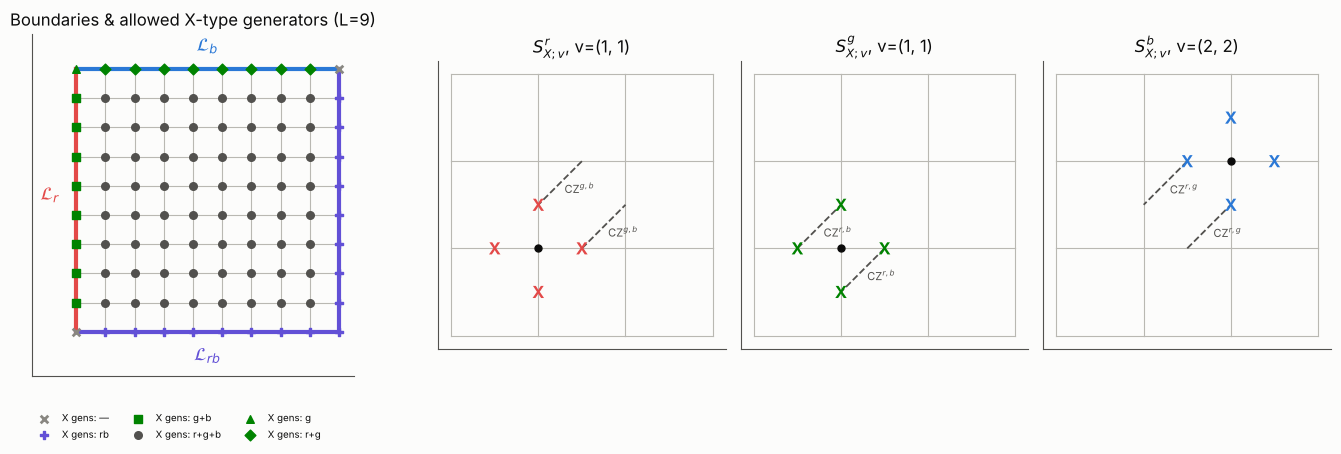

In [25]:
L_FIG = 9
lat = D4Lattice(L_FIG)
types = {}
for v in lat.vertices:
    types[v] = '+'.join(''.join(CNAME[c] for c in combo) for combo in lat.vertex_x_types(v)) or '—'
from collections import Counter as _C
print('X-generator types per vertex class (L=9):')
cls = {}
for v, t in types.items():
    x, y = v
    key = ('bulk' if 0 < x < L_FIG and 0 < y < L_FIG else
           'corner(0,0)' if v == (0, 0) else 'corner(0,L)' if v == (0, L_FIG) else
           'corner(L,L)' if v == (L_FIG, L_FIG) else 'corner(L,0)' if v == (L_FIG, 0) else
           'L_r (left)' if x == 0 else 'L_b (top)' if y == L_FIG else 'L_rb (bottom/right)')
    cls.setdefault(key, set()).add(t)
for k, v in cls.items():
    print(f'  {k:22s}: {sorted(v)}')

fig = plt.figure(figsize=(14, 4.6))
gsp = fig.add_gridspec(1, 4, width_ratios=[1.6, 1, 1, 1])
ax = fig.add_subplot(gsp[0]); ax.grid(False)
bcol = {'Lr': C_R, 'Lb': C_B, 'Lrb': '#6250d6', None: '#b9b8b2'}
for e in range(lat.E):
    (x0, y0), (x1, y1) = lat.endpoints(e)
    bd = lat.boundary_of_edge(e)
    ax.plot([x0, x1], [y0, y1], color=bcol[bd], lw=3 if bd else 0.8, zorder=1)
mk = {'r+g+b': ('o', '#52514e'), 'g+b': ('s', C_G), 'r+g': ('D', C_G), 'g': ('^', C_G), 'rb': ('P', '#6250d6'), '—': ('x', '#898781')}
seen = set()
for v, t in types.items():
    m, c = mk[t]
    ax.scatter(*v, marker=m, color=c, s=30, zorder=3, label=None if t in seen else f'X gens: {t}')
    seen.add(t)
ax.set_title('Boundaries & allowed X-type generators (L=9)')
ax.text(-0.9, L_FIG / 2, r'$\mathcal{L}_r$', color=C_R, fontsize=13, ha='center')
ax.text(L_FIG / 2, L_FIG + 0.6, r'$\mathcal{L}_b$', color=C_B, fontsize=13, ha='center')
ax.text(L_FIG / 2, -1.0, r'$\mathcal{L}_{rb}$', color='#6250d6', fontsize=13, ha='center')
ax.set_aspect('equal'); ax.legend(loc='upper left', bbox_to_anchor=(-0.02, -0.08), fontsize=7, ncol=3)
ax.set_xlim(-1.5, L_FIG + 0.5); ax.set_ylim(-1.5, L_FIG + 1.2); ax.set_xticks([]); ax.set_yticks([])
lat4 = D4Lattice(3)
def mid(q):
    (x0, y0), (x1, y1) = lat4.endpoints(q // 3)
    return (x0 + x1) / 2, (y0 + y1) / 2
for k, (c, col) in enumerate([(R, C_R), (G, C_G), (B, C_B)]):
    ax = fig.add_subplot(gsp[k + 1]); ax.grid(False)
    for e in range(lat4.E):
        (x0, y0), (x1, y1) = lat4.endpoints(e)
        ax.plot([x0, x1], [y0, y1], color='#b9b8b2', lw=0.8)
    v = (1, 1) if c != B else (2, 2)
    if c == G: v = (1, 1)
    op = lat4.SX(v, c)
    ax.scatter(*v, color='#0b0b0b', s=25, zorder=3)
    for qq in op.s:
        x, y = mid(qq); ax.text(x, y, 'X', color=col, ha='center', va='center', fontsize=12, weight='bold')
    for (i, j) in op.quad:
        (xa, ya), (xb, yb) = mid(i), mid(j)
        ax.plot([xa, xb], [ya, yb], ls='--', color='#52514e', lw=1.3)
        cols_ = ''.join(sorted([CNAME[i % 3], CNAME[j % 3]], key='rgb'.index))
        ax.text((xa + xb) / 2 + 0.05, (ya + yb) / 2 - 0.12, f'CZ$^{{{cols_[0]},{cols_[1]}}}$', fontsize=8, color='#52514e')
    ax.set_title(f'$S^{CNAME[c]}_{{X;v}}$, v={v}')
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(f'{FIGURES}/d4_lattice_and_stabilizers.png', dpi=150); plt.show()

右図：$S^r_X$ の CZ$^{g,b}$ は頂点の右上の plaquette（$v$ = 頂点0）、$S^g_X$ の CZ$^{r,b}$ は左上（$v$ = 頂点1）と右下（$v$ = 頂点2）、$S^b_X$ の CZ$^{r,g}$ は左下（$v$ = 頂点3）。これは [KZH] Fig. 4 の破線の位置と一致する。

## 2. 符号データ：生成元数・論理量子ビット数・符号距離

* $k$：$\dim C_Z - \mathrm{rank}(\text{shifts})$（生成元の $C_Z$ 上での可換性・$S^2=1$ と併せて検証ノートで確認）。
* $d_Z$：論理 $Z$ 型 Pauli の最小重み。$d_X^{\rm shift}$：$C_Z$ に属し安定化子シフトの張る空間に属さない $X$ シフトの最小重み（D4相では CZ 修飾があるため、これは Knill–Laflamme 距離そのものではない。$L=2$ のみ KL 条件を直接検査）。
* いずれも厳密 MILP（HiGHS）。

In [26]:
import time
rows = []
for L in range(1, DIST_L_MAX + 1):
    t0 = time.time()
    lat = D4Lattice(L)
    d4 = CodeData(lat); fsc = CodeData(lat, (R, B), dressed=False)
    c4, cf = code_consistency(d4), code_consistency(fsc)
    dz4, dx4, _, _ = distances(d4); dzf, dxf, _, _ = distances(fsc)
    rows.append(dict(L=L, D4_qubits_incl_frozen=d4.lat.n, D4_xgens=len(d4.xgens), D4_k=c4['k'],
                     D4_commuting_on_CZ=not c4['noncommuting_pairs'], D4_dZ=dz4, D4_dX_shift=dx4,
                     FSC_k=cf['k'], FSC_dZ=dzf, FSC_dX=dxf, seconds=round(time.time() - t0, 2)))
code_df = pd.DataFrame(rows)
code_df.to_csv(f'{RESULTS}/d4_code_table.csv', index=False)
code_df

,L,D4_qubits_incl_frozen,D4_xgens,D4_k,D4_commuting_on_CZ,D4_dZ,D4_dX_shift,FSC_k,FSC_dZ,FSC_dX,seconds
0,1,12,2,1,True,1,4,1,1,4,0.68
1,2,36,11,1,True,2,5,1,2,5,0.06
2,3,72,26,1,True,3,6,1,3,6,0.19
3,4,120,47,1,True,4,7,1,4,7,0.51
4,5,180,74,1,True,5,8,1,5,8,1.11
5,6,252,107,1,True,6,9,1,6,9,2.19
6,7,336,146,1,True,7,10,1,7,10,5.36
7,8,432,191,1,True,8,11,1,8,11,20.82


**結果**：調べた全ての $L$ で $k=1$、$d_Z = L$、$X$ 型シフト距離 $= L+3$（D4・FSC とも）。
* FSC（CSS 符号）の符号距離は厳密に $\min(d_Z,d_X)=L$。
* D4 相（非 Pauli 符号）では $d_Z=L$ の論理 $Z$ があるので距離 $\le L$。下界は検証ノート V5b で、重み $\le L-1$ の全 Pauli が Knill–Laflamme 条件を満たすことを $L\le5$（`FULL_KL=True` で $L=6$）について厳密に示した（$=L$）。それより大きな $L$ では D4 相の距離は**未証明**（上界 $L$ のみ）。
* よって比較の横軸は **$L$（= FSC の距離 = 入出力符号の距離）** であり、「D4 相も距離 $L$」は $L\le5$（6）でのみ証明済みである。$X$ 方向には $3$ だけ余分な距離があり、正方形でない格子で量子ビット数を削れる可能性があるが、[KZH] の Fig. 4 の正方形配置に従う（最適化はしていない）。

## 3. 段階別の資源計数

`D4CostData(L)` は明示的な格子上で、各段階の回路を**ゲート単位で構成**して数える：
* ラウンド回路：各生成元に測定補助1個。$X$ 型 Clifford 安定化子 $S = X(s)\prod CZ$ は「補助 $|+\rangle$ → CNOT（補助→データ） → CCZ（補助, $i$, $j$） → $X$ 測定」（制御-$S$ による標準的な測定。**この回路は [KZH] には書かれておらず本研究の構成**。正しさは検証ノートで密行列により確認）。
* frozen 量子ビット（境界の単一量子ビット $Z$ 安定化子で $|0\rangle$ に固定）は割り当てず、それに作用するゲート（恒等になる）も除く。$\mathcal L_{rb}$ の $g$ 量子ビットを除くため、そこでの $V$ の CNOT 対（$Z^rZ^b=+1$ 上で恒等）も除く。
* S3 の CZ 補正は最悪ケース（全頂点）で数える（期待値はその半分；$\kappa$ が一様であることは検証ノートで統計的に確認）。

In [27]:
stage_df, sum_df, blocks = d4_resource_tables(D_LIST, DUR, PARAMS)
stage_df.to_csv(f'{RESULTS}/d4_stage_costs.csv', index=False)
sum_df.to_csv(f'{RESULTS}/d4_summary.csv', index=False)
json.dump(dict(params=PARAMS, dur=DUR, blocks=blocks), open(f'{RESULTS}/d4_blocks.json', 'w'), indent=1)
print('saved', len(stage_df), 'stage rows')

Kobayashi d=3: 0.0s
Kobayashi d=5: 0.1s


Kobayashi d=7: 0.3s


Kobayashi d=9: 0.4s


Kobayashi d=11: 0.7s


Kobayashi d=13: 1.2s


Kobayashi d=15: 2.1s
saved 672 stage rows


### 3.1 段階別の表（$d=9$、`FT_ref`、比較A、原始ゲートセット、データ＋測定補助）
`rounds` は符号ごとのラウンド数（S0, S4 は FSC のラウンド、S1 は D4 のラウンド）。`time_lb/ub` は物理時間（全ゲート1単位の仮定）の下界／上界。`source` は値の出所（文献／明示的回路からの計数／仮定パラメータ／未解決）。

In [28]:
d_show = 9 if 9 in D_LIST else D_LIST[-1]
view = stage_df[(stage_df.d == d_show) & (stage_df.model == 'FT_ref') & (stage_df.comparison == 'A') &
                (stage_df.gateset == 'primitive') & (~stage_df.data_only)]
view[['stage', 'qubits', 'rounds', 'time_lb', 'time_ub', 'gates', 'source']]

,stage,qubits,rounds,time_lb,time_ub,gates,source
288,S0 FSC |+_L> preparation,683,9,73.0,127,"{""INIT_X"": 1791.0, ""INIT_Z"": 1782.0, ""CNOT"": 1...",assumption (parameter)
289,S1 switch-in (gauging) to D4,1007,9,81.0,252,"{""INIT_X"": 2178.0, ""CNOT"": 17442.0, ""CCZ"": 345...",assumption (parameter)
290,S2 transversal U = W V (logical T^dag),504,0,5.0,5,"{""CNOT"": 306.0, ""CS"": 81.0, ""CSDG"": 64.0, ""TDG...",counted (explicit circuit)
291,S3 switch-out: Z^g meas + S^g correction,504,0,2.0,2,"{""MEAS_Z"": 162.0, ""CZ"": 128.0}",counted (explicit circuit)
292,S4 FSC error-correction rounds,683,9,72.0,126,"{""INIT_X"": 1449.0, ""CNOT"": 11934.0, ""MEAS_X"": ...",assumption (parameter)
293,S5 logical X frame: T^dag|+> -> T|+>,0,0,0.0,0,{},counted (explicit circuit)


### 3.2 1ラウンドあたりのコストと定数深さ段階

In [29]:
rows = []
for d in D_LIST:
    b = blocks[f'{d}|primitive']; bd = blocks[f'{d}|clifford_t']
    rows.append(dict(d=d, FSC_round_lb=b['round']['FSC']['time_lb'], FSC_round_ub=b['round']['FSC']['time_ub'],
                     D4_round_lb=b['round']['D4']['time_lb'], D4_round_ub=b['round']['D4']['time_ub'],
                     D4_round_ub_cliffordT=bd['round']['D4']['time_ub'], D4g_round_ub=b['round']['D4g']['time_ub'],
                     CCZ_per_D4_round=b['round']['D4']['gates'].get('CCZ', 0),
                     CNOT_per_D4_round=b['round']['D4']['gates'].get('CNOT', 0),
                     U_depth_time=b['U_time'], switch_out_time=b['out_time'],
                     U_CS=b['U_gates'].get('CS', 0) + b['U_gates'].get('CSDG', 0), U_TDG=b['U_gates'].get('TDG', 0)))
per_round_df = pd.DataFrame(rows); per_round_df

,d,FSC_round_lb,FSC_round_ub,D4_round_lb,D4_round_ub,D4_round_ub_cliffordT,D4g_round_ub,CCZ_per_D4_round,CNOT_per_D4_round,U_depth_time,switch_out_time,U_CS,U_TDG
0,3,8.0,14,9.0,28,60,8,24,210,5,2,13,6
1,5,8.0,14,9.0,28,60,8,96,594,5,2,41,10
2,7,8.0,14,9.0,28,60,8,216,1170,5,2,85,14
3,9,8.0,14,9.0,28,60,8,384,1938,5,2,145,18
4,11,8.0,14,9.0,28,60,8,600,2898,5,2,221,22
5,13,8.0,14,9.0,28,60,8,864,4050,5,2,313,26
6,15,8.0,14,9.0,28,60,8,1176,5394,5,2,421,30


## 4. 符号距離に対するスケーリング（厳密な多項式の同定）

数値はすべて明示的な格子上の計数なので、$L$ の多項式になることが期待される。最初の4点で補間した（高々3次の）多項式が**残りすべての点で厳密に一致するか**を確認する（一致しなければ「多項式ではない／境界の効果がまだある」と表示）。これは評価範囲の $L$ についての恒等式の確認であり、全ての $L$ についての証明ではない（ただし量子ビット数・ゲート数は格子の局所構造から $L$ の2次式、体積は $\lceil\kappa d\rceil$ ラウンドを掛けて3次式になる）。

In [30]:
import sympy
x = sympy.Symbol('d')
def identify(values):
    Ls = sorted(values)
    if len(Ls) < 5:
        return None, False
    p = sympy.interpolate([(L, values[L]) for L in Ls[:4]], x)      # cubic through 4 points
    ok = all(sympy.nsimplify(p.subs(x, L) - values[L]) == 0 for L in Ls)
    return sympy.expand(p), ok
quant = {
    'peak qubits (D4 phase: data+anc)': {d: blocks[f'{d}|primitive']['n_total'] for d in D_LIST},
    'FSC qubits (data+anc)': {d: blocks[f'{d}|primitive']['n']['fsc_data'] + blocks[f'{d}|primitive']['n']['fsc_anc'] for d in D_LIST},
    'D4 data qubits': {d: blocks[f'{d}|primitive']['n']['d4_data'] for d in D_LIST},
    'CCZ per D4 round': {d: blocks[f'{d}|primitive']['round']['D4']['gates'].get('CCZ', 0) for d in D_LIST},
    'CNOT per D4 round': {d: blocks[f'{d}|primitive']['round']['D4']['gates'].get('CNOT', 0) for d in D_LIST},
}
for comp in ['A']:
    for model in ['FT_ref', 'NL_min']:
        sel = sum_df[(sum_df.model == model) & (sum_df.comparison == comp) & (sum_df.gateset == 'primitive') & (~sum_df.data_only)]
        quant[f'V [qubit*round] {model}'] = dict(zip(sel.d, sel.V_qubit_round))
        quant[f'V [qubit*time] lb {model}'] = dict(zip(sel.d, sel.V_qubit_time_lb))
        quant[f'V [qubit*time] ub {model}'] = dict(zip(sel.d, sel.V_qubit_time_ub))
        quant[f'rounds {model}'] = dict(zip(sel.d, sel.rounds))
poly_rows = []
for k, v in quant.items():
    p, ok = identify({d: int(round(val)) for d, val in v.items()})
    poly_rows.append(dict(quantity=k, polynomial_in_d=str(p), exact_on_all_points=ok))
poly_df = pd.DataFrame(poly_rows); poly_df.to_csv(f'{RESULTS}/d4_polynomials.csv', index=False); poly_df

,quantity,polynomial_in_d,exact_on_all_points
0,peak qubits (D4 phase: data+anc),12*d**2 + 4*d - 1,True
1,FSC qubits (data+anc),8*d**2 + 4*d - 1,True
2,D4 data qubits,6*d**2 + 2*d,True
3,CCZ per D4 round,6*d**2 - 12*d + 6,True
4,CNOT per D4 round,24*d**2 - 6,True
5,V [qubit*round] FT_ref,28*d**3 + 12*d**2 - 3*d,True
6,V [qubit*time] lb FT_ref,236*d**3 + 150*d**2 - 7*d - 1,True
7,V [qubit*time] ub FT_ref,560*d**3 + 274*d**2 - 38*d - 1,True
8,rounds FT_ref,3*d,True
9,V [qubit*round] NL_min,15*d**2 + 6*d - 1,True


`FT_ref` の体積の多項式は $\kappa_0=\kappa_{in}=\kappa_{out}=1$（**仮定**）に対するもの。一般の $\kappa$ では、主要項は
$$V_{\rm qubit\cdot round}\simeq \big(8\kappa_0 + 12\kappa_{in} + 8\kappa_{out}\big)\,d^3$$
（FSC 相の量子ビット数 $=8d^2+4d-1$、D4 相 $=12d^2+4d-1$、いずれもデータ＋測定補助）。

## 5. 図：段階別の内訳と量子ビット数

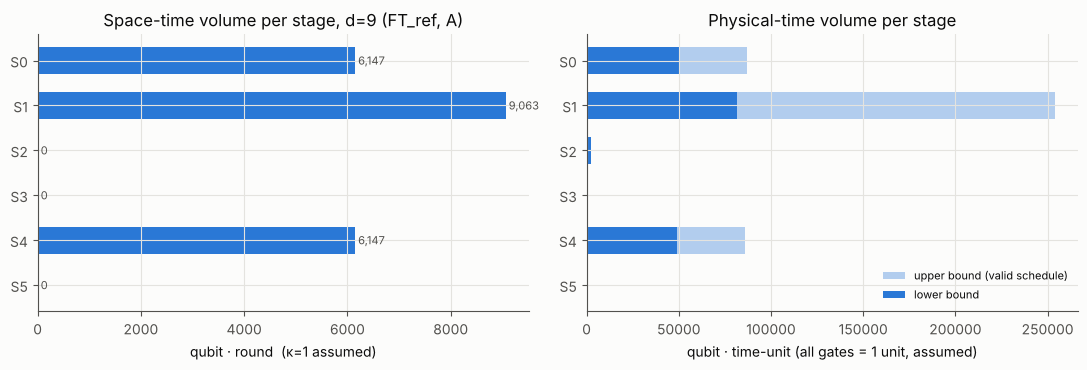

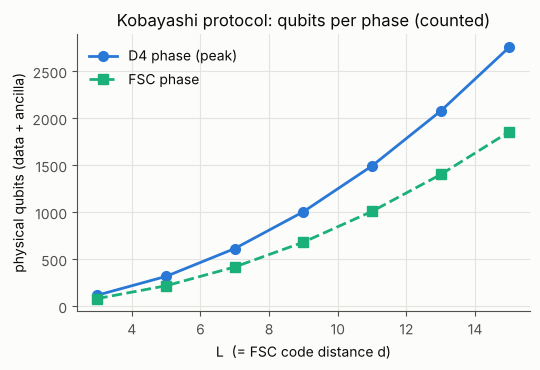

In [31]:
sel = stage_df[(stage_df.d == d_show) & (stage_df.model == 'FT_ref') & (stage_df.comparison == 'A') &
               (stage_df.gateset == 'primitive') & (~stage_df.data_only)].copy()
sel['V_round'] = sel.qubits * sel.rounds
sel['V_time_lb'] = sel.qubits * sel.time_lb
sel['V_time_ub'] = sel.qubits * sel.time_ub
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
lab = [s.split(' ')[0] for s in sel.stage]
axes[0].barh(lab, sel.V_round, color=C_KOB, height=0.6)
axes[0].invert_yaxis(); axes[0].set_xlabel('qubit · round  (κ=1 assumed)')
axes[0].set_title(f'Space-time volume per stage, d={d_show} (FT_ref, A)')
for i, v in enumerate(sel.V_round):
    axes[0].text(v, i, f' {int(v):,}', va='center', fontsize=8, color='#52514e')
axes[1].barh(lab, sel.V_time_ub, color=C_KOB, alpha=0.35, height=0.6, label='upper bound (valid schedule)')
axes[1].barh(lab, sel.V_time_lb, color=C_KOB, height=0.6, label='lower bound')
axes[1].invert_yaxis(); axes[1].set_xlabel('qubit · time-unit (all gates = 1 unit, assumed)')
axes[1].set_title('Physical-time volume per stage'); axes[1].legend(loc='lower right', fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIGURES}/d4_stage_breakdown.png', dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(5.5, 3.8))
ds = np.array(D_LIST)
ax.plot(ds, [blocks[f'{d}|primitive']['n_total'] for d in D_LIST], 'o-', color=C_KOB, label='D4 phase (peak)')
ax.plot(ds, [blocks[f'{d}|primitive']['n']['fsc_data'] + blocks[f'{d}|primitive']['n']['fsc_anc'] for d in D_LIST],
        's--', color=C_AUX, label='FSC phase')
ax.set_xlabel('L  (= FSC code distance d)'); ax.set_ylabel('physical qubits (data + ancilla)')
ax.set_title('Kobayashi protocol: qubits per phase (counted)'); ax.legend()
plt.tight_layout(); plt.savefig(f'{FIGURES}/d4_qubits_vs_d.png', dpi=150); plt.show()

## 6. 解釈と注意

* **数えたもの**：明示的な格子・回路から数えた量子ビット数、ゲート数、ラウンドあたりの物理時間（下界・上界）。
* **仮定に依存するもの**：`FT_ref` のラウンド数（$\kappa$）。[KZH] は $O(d)$ としか述べておらず、JIT decoder の文献 [Dav] の全文は本環境から参照できなかった。ゲート所要時間（全て1単位）。
* **数えていないもの**：JIT decoder／matching・RG decoder の古典計算時間、制御系の遅延、FSC→通常パッチ変換（比較Bで未解決として扱う）。
* D4 相の 1 ラウンドは CCZ を含むため、FSC や回転表面符号の 1 ラウンドより深い（上の表）。**異なる符号のラウンド数を同一の時間単位とみなさない**ため、比較では物理時間でも示す。
* `FT_ref` では物理 CCZ が $6(d-1)^2$ 個／ラウンド × $\lceil\kappa_{in}d\rceil$ ラウンド $=\Theta(d^3)$ 必要になる。ノイズなしでは問題にならないが、ノイズありの拡張では重要な資源になる（比較Bで T 数としても表示）。